# Application 2: larger circuits and what they cost

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bsc-wdc/qdislib/blob/main/notebooks/applications/02_scaling.ipynb) [![Open in Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/bsc-wdc/qdislib/main?labpath=notebooks/applications/02_scaling.ipynb)

Two circuits larger than the earlier ones: **N2 on 12 qubits**, with a Hamiltonian of 383 terms, and a **25-qubit lattice**, cut into four blocks. Then the question that decides whether a cut is usable: how the error grows with the number of cuts.

The ansatzes are not optimised, so these energies are not ground-state energies. The point is the reconstruction: its agreement with the exact value, and what it took. The notebook runs serially; its shot runs are the slowest part, and under PyCOMPSs they run as tasks (notebook 09).

In [1]:
# Installs Qdislib on Colab or Binder; does nothing where Qdislib 2 is installed.
try:
    import Qdislib
    assert Qdislib.__version__.startswith("2.")
except (ImportError, AssertionError):
    %pip install -q "qdislib[qiskit]>=2.0"

In [2]:
%matplotlib inline
import json
import os
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
import Qdislib as qd


def hardware_efficient(n, seed=1):
    """A generic n-qubit ansatz: RY layer, a line of CZ gates, RY layer."""
    rng = np.random.default_rng(seed)
    qc = QuantumCircuit(n)
    for q in range(n):
        qc.ry(float(rng.uniform(0, np.pi)), q)
    for q in range(n - 1):
        qc.cz(q, q + 1)
    for q in range(n):
        qc.ry(0.3, q)
    return qc

## N2 on 12 qubits

In the STO-3G basis N2 takes 20 qubits and thousands of Pauli terms. An **active space**, CAS(6,6), keeps 6 electrons in 6 orbitals: 12 qubits and 383 terms. The notebook loads a precomputed copy. Generating it takes `pyscf` and `openfermion`, which are not Qdislib dependencies:

```python
# pip install pyscf openfermion openfermionpyscf  (not run here)
from openfermion import MolecularData, jordan_wigner
from openfermionpyscf import run_pyscf

geometry = [("N", (0, 0, 0)), ("N", (0, 0, 1.10))]
molecule = run_pyscf(MolecularData(geometry, "sto-3g", 1, 0), run_scf=1, run_fci=1)
hamiltonian = molecule.get_molecular_hamiltonian(occupied_indices=range(4), active_indices=range(4, 10))
qubit_op = jordan_wigner(hamiltonian)   # 383 Pauli terms
```

In [3]:
path = os.path.join("data", "n2_cas66_hamiltonian.json")
if not os.path.exists(path):    # on Colab only the notebook is there
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/bsc-wdc/qdislib/main/notebooks/applications/data/n2_cas66_hamiltonian.json",
        path,
    )
with open(path) as handle:
    n2 = json.load(handle)
hamiltonian_n2 = [(c, pauli) for c, pauli in n2["terms"]]
print(n2["n_qubits"], "qubits,", len(hamiltonian_n2), "terms, FCI reference", round(n2["fci_energy"], 4), "Ha")

ansatz_n2 = hardware_efficient(n2["n_qubits"])
cut_n2 = qd.find_cut(ansatz_n2, max_qubits=6, wire_cut=False)
print(cut_n2, qd.cutting_overhead(ansatz_n2, cut_n2))
print(len(qd.circuit_cutting_subcircuits(ansatz_n2, cut_n2, hamiltonian_n2)), "circuits, grouped;",
      len(hamiltonian_n2) * 12, "term by term")

12 qubits, 383 terms, FCI reference -107.6541 Ha


['CZ_18'] {'subcircuits': 12, 'configurations': 6, 'fragments': 2, 'gamma': 3.0}
1920 circuits, grouped; 4596 term by term


In [4]:
start = time.time()
exact_n2 = qd.analytical_solution(ansatz_n2, hamiltonian_n2)
pieces_n2 = qd.circuit_cutting(ansatz_n2, cut_n2, hamiltonian_n2, shots=None)
print(f"uncut statevector  {exact_n2:.5f} Ha")
print(f"exact fragments    {pieces_n2:.5f} Ha   ({time.time() - start:.1f} s for both)")

start = time.time()
shots_n2 = qd.circuit_cutting(ansatz_n2, cut_n2, hamiltonian_n2, shots=4000, seed=1)
print(f"4000 shots each    {shots_n2:.5f} Ha   ({time.time() - start:.1f} s)")

uncut statevector  -104.82767 Ha
exact fragments    -104.82767 Ha   (0.9 s for both)


4000 shots each    -104.82120 Ha   (5.0 s)


## A 25-qubit lattice

A transverse-field Ising chain `H = -sum Z_i Z_{i+1} - h sum X_i` has few terms, and they fall in two commuting groups. Three cuts leave four blocks of about 6 qubits. Each block is small, and the whole energy comes from the blocks.

An uncut statevector of 25 qubits takes about 0.5 GB and is slow for 49 terms, so the reference here is the exact contraction of the fragments. The code that made it is checked against an uncut statevector further down.

In [5]:
def ising(n, h=1.0):
    terms = []
    for i in range(n - 1):
        term = ["I"] * n
        term[i] = term[i + 1] = "Z"
        terms.append((-1.0, "".join(term)))
    for i in range(n):
        term = ["I"] * n
        term[i] = "X"
        terms.append((-h, "".join(term)))
    return terms


lattice = hardware_efficient(25, seed=2)
terms = ising(25)
cut_lattice = qd.find_cut(lattice, max_qubits=7, wire_cut=False)
print(cut_lattice, qd.cutting_overhead(lattice, cut_lattice))
print(len(terms), "terms;", len(qd.circuit_cutting_subcircuits(lattice, cut_lattice, terms)), "circuits")

start = time.time()
exact_lattice = qd.circuit_cutting(lattice, cut_lattice, terms, shots=None)
print(f"exact fragments  {exact_lattice:+.4f}   ({time.time() - start:.1f} s)")

start = time.time()
shots_lattice = qd.circuit_cutting(lattice, cut_lattice, terms, shots=4000, seed=1)
print(f"4000 shots each  {shots_lattice:+.4f}   ({time.time() - start:.1f} s)")

['CZ_31', 'CZ_37', 'CZ_43'] {'subcircuits': 864, 'configurations': 216, 'fragments': 4, 'gamma': 27.0}
49 terms; 1728 circuits


exact fragments  +3.2682   (0.7 s)


4000 shots each  +3.2905   (4.5 s)


The fragments' sizes set the time of each circuit, and the number of cuts the number of circuits, so this circuit is not much harder than one half its width. The exact reconstruction is checked here on 16 qubits, in the same way, where an uncut statevector is cheap:

In [6]:
check = hardware_efficient(16, seed=2)
check_cut = qd.find_cut(check, max_qubits=7, wire_cut=False)
print(check_cut)
print(f"uncut {qd.analytical_solution(check, ising(16)):+.6f}   exact fragments {qd.circuit_cutting(check, check_cut, ising(16), shots=None):+.6f}")

['CZ_21', 'CZ_27']
uncut +2.470790   exact fragments +2.470790


## What each cut costs in shots

`gamma**2` is the worst case. To see what a run needs, compare **total shots for the same error**. With the same `shots` per circuit more cuts run many more circuits, so a run's error falls and the total goes up, and neither is the number to compare. From one run and its `error=` we get the total shots a standard error of 0.01 would take, since it scales as `1/sqrt(shots)`.

There are two 12-qubit circuits: one with small angles, whose observable is large, and one with random angles, whose observable is near zero.

small angles: exact +0.4832
  1 cuts, gamma  3: 0.482849 ± 0.022, 12000 shots; for an error of 0.01: 57,122


  2 cuts, gamma  9: 0.483571 ± 0.014, 108000 shots; for an error of 0.01: 226,247


  3 cuts, gamma 27: 0.482478 ± 0.0053, 864000 shots; for an error of 0.01: 238,682
random angles: exact -0.0107
  1 cuts, gamma  3: -0.023231 ± 0.0085, 12000 shots; for an error of 0.01: 8,735


  2 cuts, gamma  9: -0.00706213 ± 0.0035, 108000 shots; for an error of 0.01: 13,084


  3 cuts, gamma 27: -0.00887915 ± 0.00089, 864000 shots; for an error of 0.01: 6,909


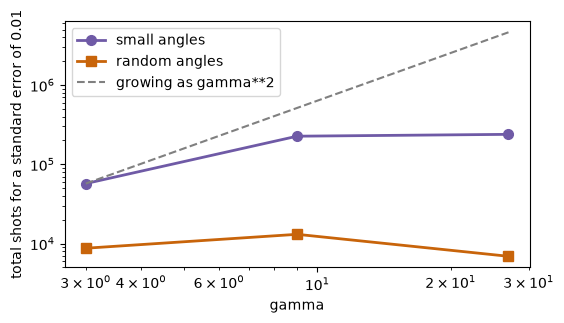

In [7]:
def chain(lo, hi, n=12, seed=3):
    rng = np.random.default_rng(seed)
    qc = QuantumCircuit(n)
    for q in range(n):
        qc.ry(float(rng.uniform(lo, hi)), q)
    for q in range(n - 1):
        qc.cz(q, q + 1)
    for q in range(n):
        qc.ry(float(rng.uniform(lo, hi)), q)
    return qc


observable = "Z" * 12
choices = [["CZ_18"], ["CZ_16", "CZ_20"], ["CZ_15", "CZ_18", "CZ_21"]]
series = {}
for label, (lo, hi) in {"small angles": (0.05, 0.3), "random angles": (0.0, 3.14)}.items():
    qc = chain(lo, hi)
    print(f"{label}: exact {qd.analytical_solution(qc, observable):+.4f}")
    series[label] = []
    for names in choices:
        gamma = qd.cutting_overhead(qc, names)["gamma"]
        value = qd.gate_cutting(qc, names, observable, shots=1000, seed=1, error=50)
        needed = value.shots * (value.error / 0.01) ** 2
        series[label].append((gamma, needed))
        print(f"  {len(names)} cuts, gamma {gamma:2.0f}: {value}, {value.shots} shots; for an error of 0.01: {needed:,.0f}")

fig, ax = plt.subplots(figsize=(6, 3.2))
for (label, points), color, marker in zip(series.items(), ["#6f5aa6", "#c8640a"], ["o", "s"]):
    gammas, needed = zip(*points)
    ax.loglog(gammas, needed, marker=marker, color=color, linewidth=2, markersize=7, label=label)
reference = [series["small angles"][0][1] * (g / 3) ** 2 for g in gammas]
ax.loglog(gammas, reference, "--", color="0.5", label="growing as gamma**2")
ax.set_xlabel("gamma")
ax.set_ylabel("total shots for a standard error of 0.01")
ax.legend()
plt.show()

On these circuits the shots grow more slowly than `gamma**2`, the worst case: the actual variance depends on the circuit and observable. So measure it, with `error=`, rather than planning from `gamma` alone (notebook 11).

## Recap

The number of circuits grows with the cuts and the commuting groups of the observable, not with the circuit's qubits. So a lattice, with few terms in few groups, can go to more qubits for the same cost, while a molecule's terms make accuracy the constraint at a modest size. Notebooks 03, 10 and 11 cover choosing cuts and shots to keep this down.